# Problem Statement:

Assignment completed by: Muniira Mohamoud

The objective is to automate the loan eligibility process based on customer details. We have a dataset that includes information such as Gender, Marital Status, Education, Number of Dependents, Income, Loan Amount, Credit History, and more.

## Step1:
**load the loan.csv file from data folder as a pandas dataframe and visualize the first 5 rows of the dataframe.**

In [1]:
import pandas as pd

# you must complete this function to load the data
def load_data(address):
    df = pd.read_csv(address) # completed, dynamic now, not hardcoded!
    return df

df = load_data('data/loan.csv')
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Step2: 
**Explore the data**

In [2]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


Missing Values: There are 22 missing values in LoanAmount, 14 missing values in Loan_Amount_Term, and 50 missing values in Credit_History. Since the dataset has 614 rows, these missing values may impact analysis and ML models.

if we assume that there are 614 rows in the data from the highest value in count, there are attributes that have much less than 614. Will affect analysis and machine learning models, Let's confirm with df.shape()

In [3]:
# confirm the row count total for loan_csv.
print(f"Data set has {df.shape[0]} rows and {df.shape[1]} columns.")

Data set has 614 rows and 12 columns.


Complete the following function to create a histogram for each of the numerical features.

**Note to self**: We are trying to see if data is normally distributed, skewed, or has outliers.

More bins = more detailed view of the distribution.

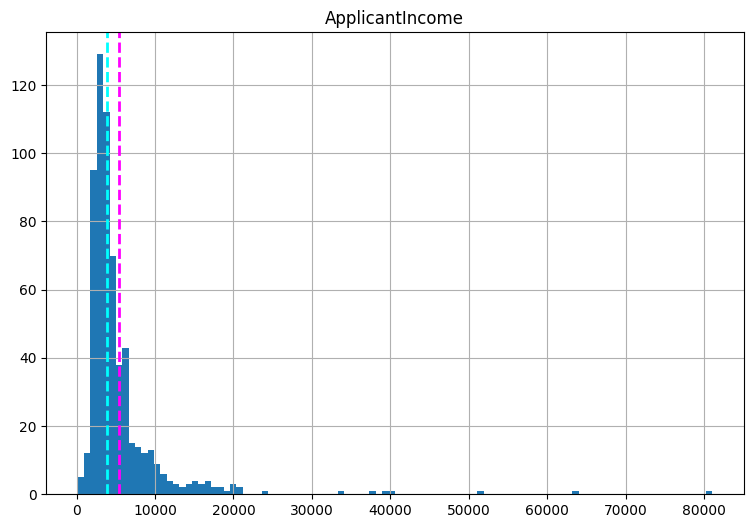

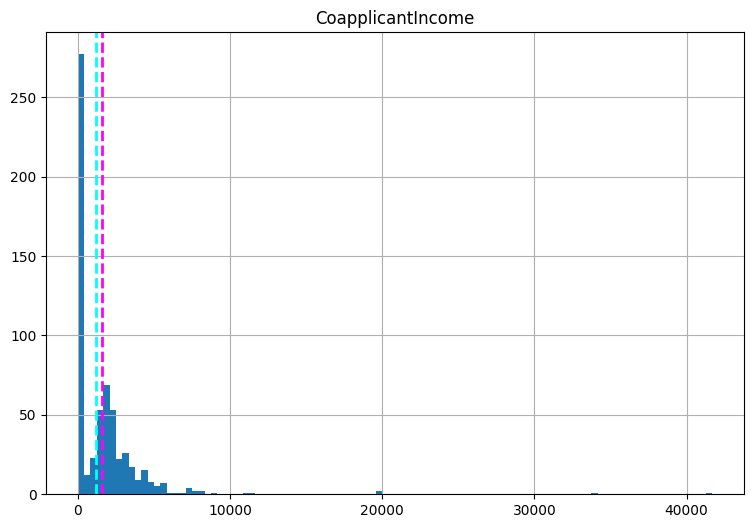

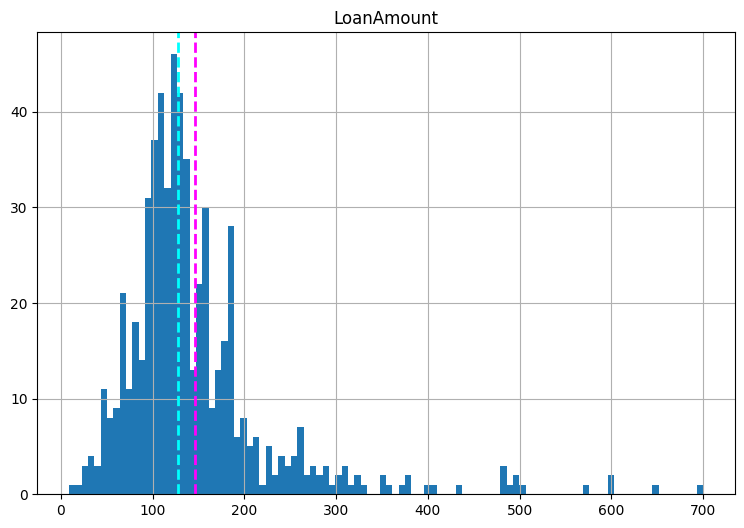

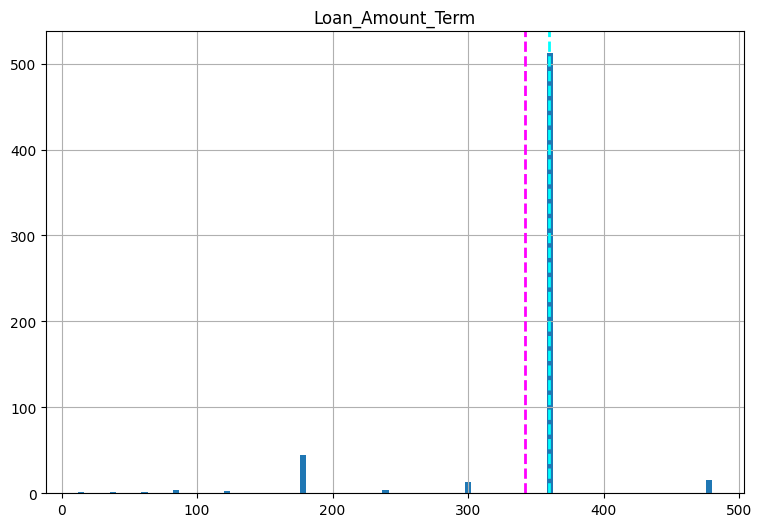

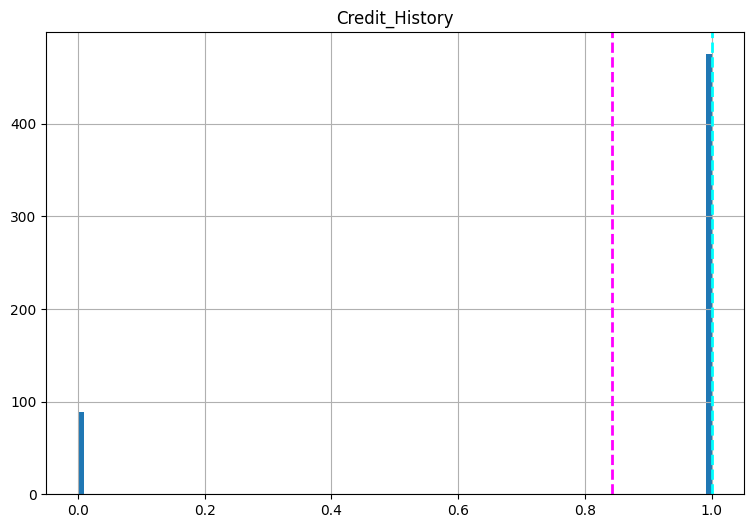

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

def plot_histogram(df, col):
    fig = plt.figure(figsize=(9, 6))
    ax = fig.gca()
    feature = df[col]
    feature.hist(bins=100, ax = ax)
    ax.axvline(feature.mean(), color='magenta', linestyle='dashed', linewidth=2)
    ax.axvline(feature.median(), color='cyan', linestyle='dashed', linewidth=2)
    ax.set_title(col)

numeric_features = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
for col in numeric_features:
    plot_histogram(df, col)
plt.show()

Now complete the following function to compare the distribution of samples per label for each feature by plotting a boxplot.

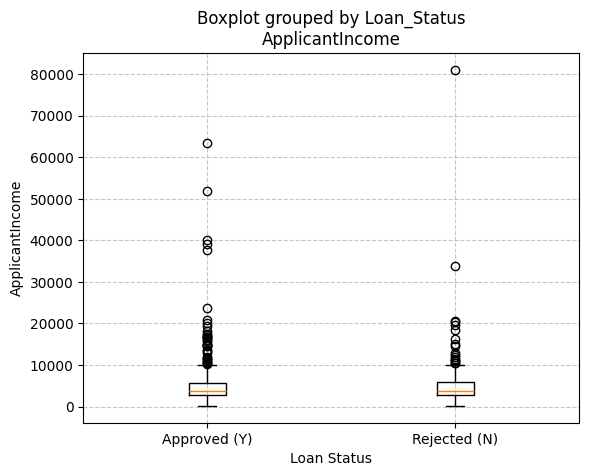

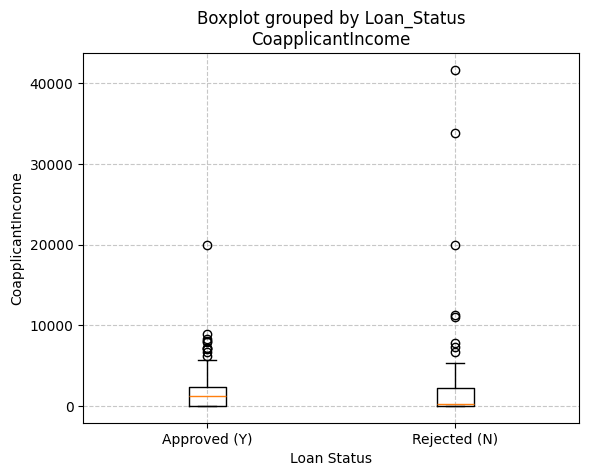

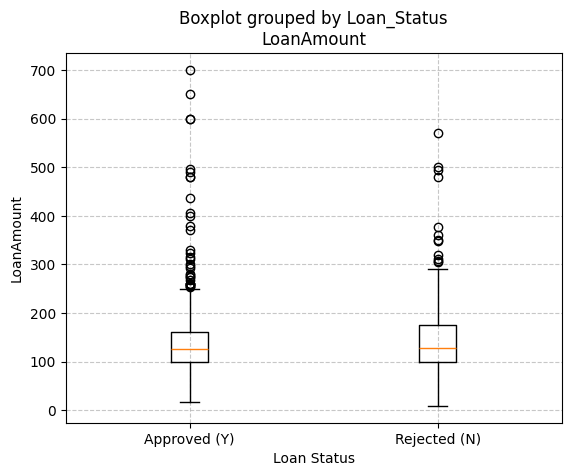

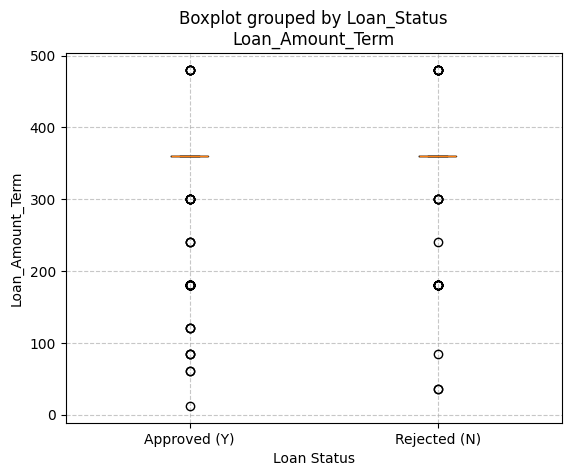

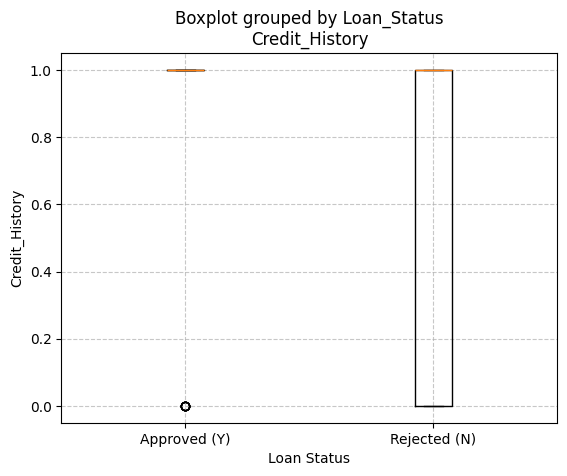

In [5]:
def plot_boxplot(df, col):
    #Complete this part#
     # Let's drop NaN values to avoid empty plots
    df_filtered = df[[col, "Loan_Status"]].dropna()

    # Convert categorical-like numerical columns to integer
    if col in ["Loan_Amount_Term", "Credit_History"]:
        df_filtered[col] = df_filtered[col].astype(int)

    approved = df_filtered[df_filtered["Loan_Status"] == "Y"][col]
    rejected = df_filtered[df_filtered["Loan_Status"] == "N"][col]

    plt.boxplot([approved, rejected], tick_labels=["Approved (Y)", "Rejected (N)"])
    plt.title(f"Boxplot grouped by Loan_Status\n{col}")
    plt.xlabel("Loan Status")
    plt.ylabel(col)
    plt.grid(True, linestyle="--", alpha=0.7)

    plt.show()

for col in numeric_features:
    plot_boxplot(df, col)

Now Complete the function below, to plot a bar chart showing the count of samples of discrete features.

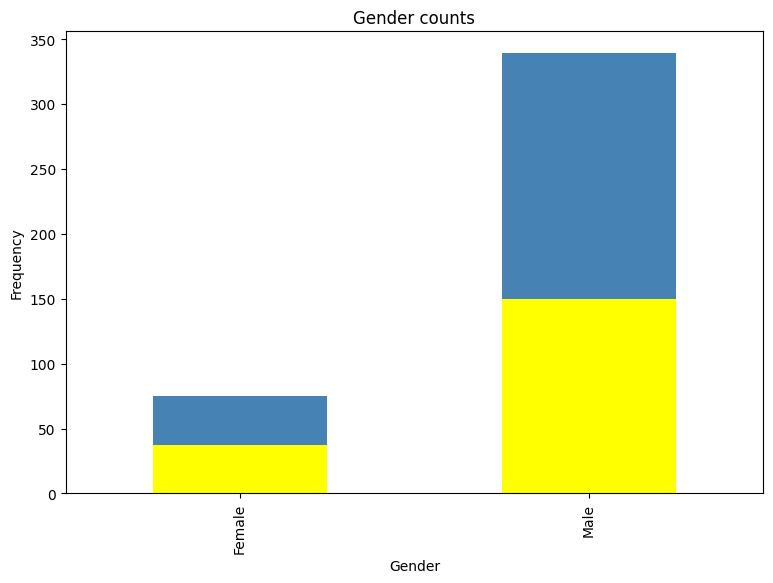

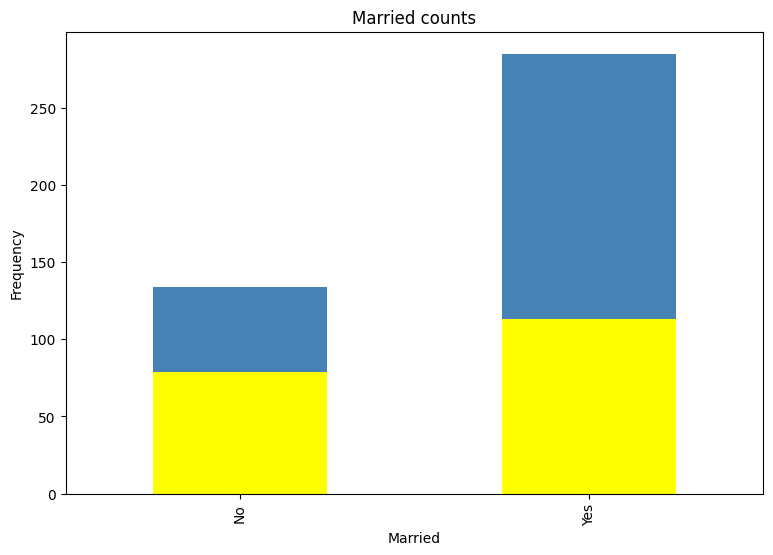

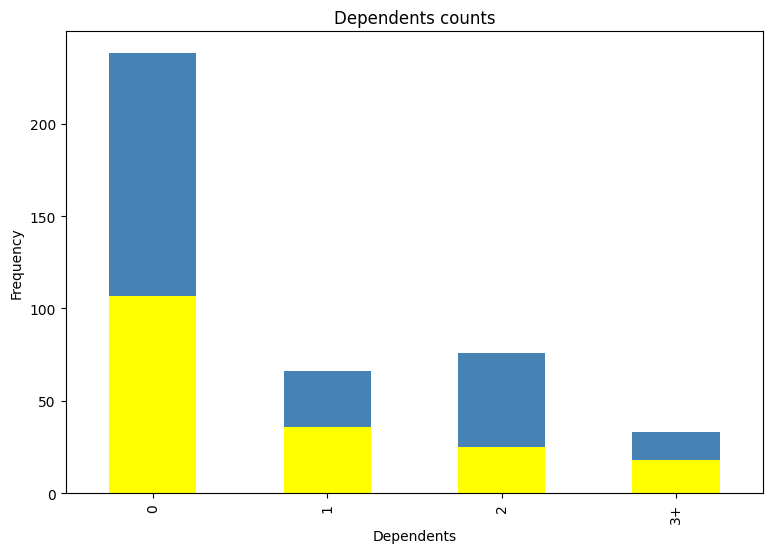

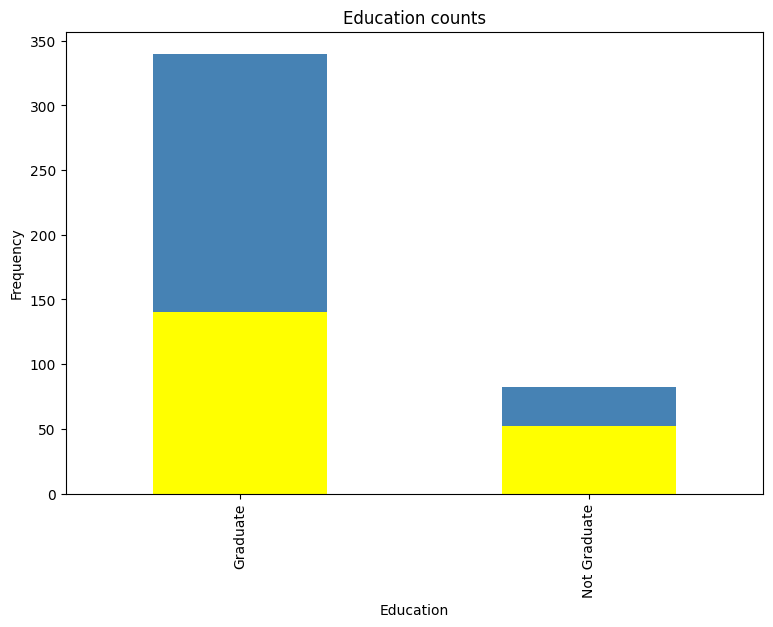

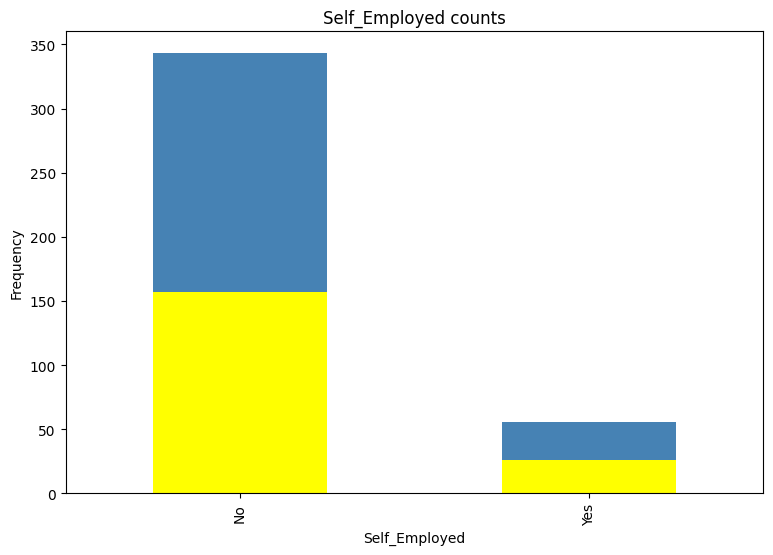

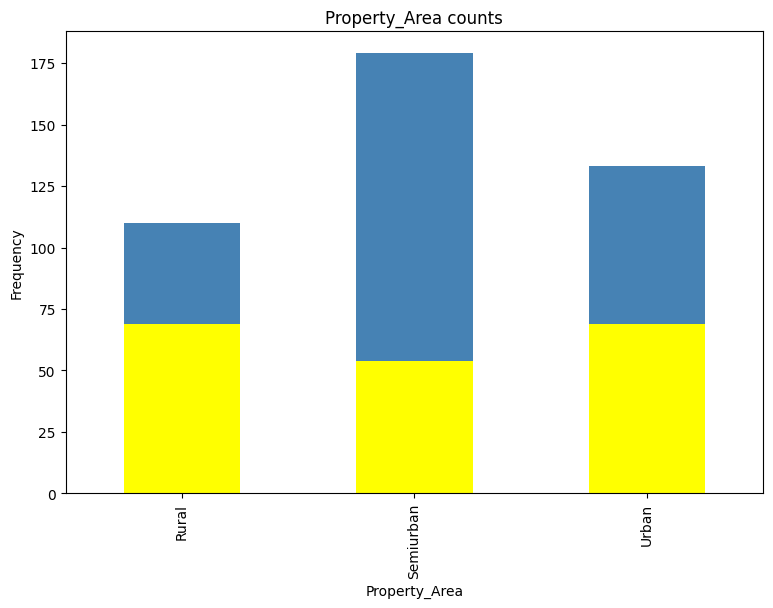

In [6]:
def plot_barchart(df, col):
    approved_counts = df[df["Loan_Status"] == "Y"][col].value_counts().sort_index()
    denied_counts = df[df["Loan_Status"] == "N"][col].value_counts().sort_index()

    fig = plt.figure(figsize=(9, 6))
    ax = fig.gca()

    approved_counts.plot.bar(ax = ax, color='steelblue')
    denied_counts.plot.bar(ax = ax, color='yellow')
    ax.set_title(col + ' counts')
    ax.set_xlabel(col) 
    ax.set_ylabel("Frequency")
    
categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

for col in categorical_features:
    plot_barchart(df, col)

---
**Question:**
- **Can you share any interesting insights or observations you made during this visualization process? Consider aspects such as feature distributions, class separation, potential outliers, or any other patterns you noticed. How might these insights inform your approach to modeling or preprocessing in the next steps?"**



**Write your answer here**

Mean: The mean compared to the standard deviation and the min, max( which is huge), 25%,50%, and 75%, is very close to the lower end, the min, and very far from the maximum. most of the data points lie around the mean somewhere, on the lower end with extreme values sitting on the higher end. ( example: the minimum income of co-applicants is 0 dollars, the mean is 1621, so why is the largest value, max, 41,667? that is a huge difference. Some applicant's incomes are $ 41,667 which is very different from the average applicant pool. Even 75% percentile is 2297, not even close to $41,667).

Next steps, we can visualize distribution, if mean > median = data is right-skewed, 50% percentile = median, mean > median, so we know it's data is right-skewed. We already have an idea but it's best to check and with a boxplot for outliers.


- Check for missing values in other columns.
- compute median, compare mean and median.
- Check for outliers (boxplot) in ApplicantIncome, CoapplicantIncome, and LoanAmount.
- Check distribution (histograms) to confirm skewness.
- Handle missing values (drop or impute).

**Boxplot**:

  *ApplicantIncome and CopapplicantIncome*:
- Both approved and rejected loans have similar distributions.
- Lots of outliers exist at high income levels.
- Some applicants with extreme income values still got rejected.
- Income alone does not determine approval.

*LoanAmount*:
- Similar median loan amounts for both approved and rejected loans.
- High variance with many outliers.
- Loan amount doe snot strongly seperate approvals and rejections.

*Loan_Amount_Term*:
- Most loan terms are 360 monts, with only a few short-term loans.
-  not very good at influencing approvals.

*Credit_History*:

- Almost all approved loans have a credit history of 1.0.
- Rejected loans have a mix of 0.0 and 1.0.
- This suggests that credit history is an important predictor for loan_status.


**Barplot**:

*Gender and Martial Status*:

- More males than females applied for loans. 
- More married applicants also are more frequent applicants than unmarried people in loan applications.
- Loan approval rates seem simlar across genders and marital status.

*Dependents and Education*:

- Most applicants have zero dependents. Number of dependents does not show clear class seperation for loan approval.
- There are way more graduates in the dataset than non-graduates.
- Graduates seem to have higher approval rates, but not a huge difference.


*Self-Employed and Property Area*:
- Most applicants are NOT self-employed.
- Self-employed people have fewer approvals, this suggests to me that type of employment may be a factor in approving or rejecting loans.
- Urban and semi-urban applicants have more approvals  than rural applicants.


**Historgrams**:


- we can see that mean > than median in histograms.
 *ApplicantIncome and Coapplicant income*:

 - Right-skewed distributions with extreme outliers (huge incomes in a few cases).
 - Most incomes cluster near the lower range, but some reach 80,000+!
 - Many coapplicants have 0 income, meaning they might not be contributing to the loan.

 *Loan Amount and Loan Term*:
 - Loan amount is right-skewed, with some extreme high loan values.
 - Loan terms are mostly 360 months (30 years), but some loans are much shorter (12 months).

 *Credit_History*:
- Most applicants have a credit history of 1(good credit).
- Rejected loans have more people with 0 credit history (bad credit).
- Credit history seems strongly correlated with loan approval. 



**Next Steps**: 

- Categorical variables should be encoded properly (One-Hot Encoding or Label Encoding).
- Handle missing and outlier values.


## Step3:
**Handling missing values**

In [7]:
def count_the_missing_values_of_each_column(df):
    missing_values_series = df.isnull().sum()
    return missing_values_series
    
missing_values_series = count_the_missing_values_of_each_column(df)
print(missing_values_series)

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


**Complete the following functions to fill the missing values based on KNN**

**Part1**:

Since KNN could only handle numercal values, we should first transform the categorical variables into numerical ones:

In [8]:
from sklearn.preprocessing import OrdinalEncoder

def generate_the_df_with_categorical_features_encoded(df, cols):
    ordinal_encoder = OrdinalEncoder()
    df_encoded = pd.DataFrame(ordinal_encoder.fit_transform(df[cols].values), columns=cols)
    df[cols] = df_encoded
    return df
    
categorical_features_with_missing_valuse = ['Gender', 'Married', 'Dependents', 'Self_Employed']

df = generate_the_df_with_categorical_features_encoded(df, categorical_features_with_missing_valuse)
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1.0,0.0,0.0,Graduate,0.0,5849,0.0,NaN,360.0,1.0,Urban,Y
1,1.0,1.0,1.0,Graduate,0.0,4583,1508.0,128.0,360.0,1.0,Rural,N
2,1.0,1.0,0.0,Graduate,1.0,3000,0.0,66.0,360.0,1.0,Urban,Y
3,1.0,1.0,0.0,Not Graduate,0.0,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,1.0,0.0,0.0,Graduate,0.0,6000,0.0,141.0,360.0,1.0,Urban,Y


**part2**: 

Now that we've transformed the data lets use KNN to impute the missing values:

In [9]:
from sklearn.impute import KNNImputer
import numpy as np

def impute_the_Gender_missing_values(df):  
    knn_imputer = KNNImputer(n_neighbors=5)
    numeric_columns = df.select_dtypes(include=[np.number]).columns
    df[numeric_columns] = pd.DataFrame(knn_imputer.fit_transform(df[numeric_columns]), columns=numeric_columns)
    return df

df = impute_the_Gender_missing_values(df)

In [10]:
missing_values_series = count_the_missing_values_of_each_column(df)
print(missing_values_series)

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [11]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1.0,0.0,0.0,Graduate,0.0,5849.0,0.0,147.8,360.0,1.0,Urban,Y
1,1.0,1.0,1.0,Graduate,0.0,4583.0,1508.0,128.0,360.0,1.0,Rural,N
2,1.0,1.0,0.0,Graduate,1.0,3000.0,0.0,66.0,360.0,1.0,Urban,Y
3,1.0,1.0,0.0,Not Graduate,0.0,2583.0,2358.0,120.0,360.0,1.0,Urban,Y
4,1.0,0.0,0.0,Graduate,0.0,6000.0,0.0,141.0,360.0,1.0,Urban,Y


## Step4:

**Preparing data for prediction**

Now complete the following function to separate features from labels and then split the training set from testing set with test_size being 30% of the data and set the random_state to be zero

In [12]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

def separate_features_from_label_and_split_the_data(df, features, label, test_size=0.3, random_state=0):
    # Encode the target variable using LabelEncoder
    label_encoder = LabelEncoder()
    df['Loan_Status'] = label_encoder.fit_transform(df['Loan_Status'])
    # Separate features from label
    X, y = df[features], df[label]
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)
    return X_train, X_test, y_train, y_test
    
features = ['Gender','Married','Dependents','Education','Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History',
            'Property_Area']
label = 'Loan_Status'

X_train, X_test, y_train, y_test = separate_features_from_label_and_split_the_data(df, features, label, test_size=0.3, random_state=0)

print ('Training cases: %d\nTest cases: %d' % (X_train.shape[0], X_test.shape[0]))

Training cases: 429
Test cases: 185


## Step5:

**Lets begin by training a KNN model**

First complete the following function to generate a pipeline:

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.neighbors import KNeighborsClassifier

def generate_knn_pipeline(df, ordinal_categorical_feature, onehot_categorical_feature, numerical_features):
    # Define categorical and numerical features
    c1_idx = [df.columns.get_loc(item) for item in ordinal_categorical_feature]
    c2_idx = [df.columns.get_loc(item) for item in onehot_categorical_feature]
    n_idx = [df.columns.get_loc(item) for item in numerical_features]
    
    # Create transformers for numerical and categorical features
    ordinal_categorical_transformer = OrdinalEncoder()
    
    onehot_categorical_transformer =  OneHotEncoder(handle_unknown='ignore')

    numerical_transformer = Pipeline(steps=[
        ('imputer', KNNImputer()),  # Using KNN to fill in missing values
        ('scaler', StandardScaler())  # standardizes numerical features
    ])
    
    # Apply transformers to features using ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat1', ordinal_categorical_transformer, c1_idx),
            ('cat2', onehot_categorical_transformer, c2_idx),
            ('num', numerical_transformer, n_idx),
        ])
    
    # Define the KNN model
    knn_model = KNeighborsClassifier(n_neighbors=3)
    
    # Create the pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', knn_model)
    ])

    return pipeline

ordinal_categorical_feature = ['Education']
onehot_categorical_feature = ['Property_Area']
numerical_features = df.columns.difference(ordinal_categorical_feature + onehot_categorical_feature + ['Loan_Status'])

pipeline = generate_knn_pipeline(df, ordinal_categorical_feature, onehot_categorical_feature, numerical_features)

---
**Question:**
- **We have employed both the Ordinal encoder and the OneHot encoder in this exercise for encoding different categorical features. Can you provide a rationale for the choice of encoder for each feature? In other words, why did we choose to use the Ordinal encoder for certain features and the OneHot encoder for others? What considerations or characteristics of the features have influenced our decision in selecting the appropriate encoder for each case?**

**Write your answer here**

**The reasons for choosing ordinalEncoder**: The Ordinal Encoder assigns an integer value to each category. This is important when categories have a clear order or ranking. The order has meaning and could impact the model's decision if not properly encoded based on category type. ordinal enconding will help the model recognize and learn from the inherrent ranking within these features.

- Education: Assume order because graduates are typically to have a higher level of education than non-graduates.

- Dependents: More dependents generally imply a larger family size, in dataset we see 0, 1,2,3+.

- Gender, Married, Self-Employed: These seem nominal to me, seeing how they are used in this project, makes me believe they are encoded using ordinal encoder because they only have 2 categories and may have slight meaning  that does not imply significant order , easier to use ordinal here.

**The reasons for choosing OneHot Encoder**:
The OneHot encoder creates binary columns for each category equally as in no inherent order. This is great for nominal variables, categories that do not have an inherent ranking.

- Property_Area: The categories, urban, semiurban, and rural are nominal categories. No area is ranked higher than others in it's meaning, they are just different categories. 





Now complete the following snippet to make prediction and evaluate the results:

In [14]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score

# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Get predictions from test data
predictions = pipeline.predict(X_test)

# Get evaluation metrics
cm = confusion_matrix(y_test, predictions)
print('Confusion Matrix:\n',cm, '\n')
print('Accuracy:', accuracy_score(y_test,predictions))
print("Overall Precision:", precision_score(y_test,predictions))
print("Overall Recall:", recall_score(y_test,predictions))

Confusion Matrix:
 [[ 26  25]
 [ 17 117]] 

Accuracy: 0.772972972972973
Overall Precision: 0.823943661971831
Overall Recall: 0.8731343283582089


## Step6: 
**Lets make the pipeline comprehensive and include the missing value imputation in the pipeline**

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

df = load_data('data/loan.csv')

# Encode the target variable using LabelEncoder
label_encoder = LabelEncoder()
df['Loan_Status'] = label_encoder.fit_transform(df['Loan_Status'])

X_train, X_test, y_train, y_test = separate_features_from_label_and_split_the_data(df, features, label, test_size=0.3, random_state=0)

# Define categorical and numerical features
ordinal_categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed']
c1_idx = [df.columns.get_loc(item) for item in ordinal_categorical_features]
onehot_categorical_features = ['Property_Area']
c2_idx = [df.columns.get_loc(item) for item in onehot_categorical_features]
numerical_features = df.columns.difference(ordinal_categorical_features + onehot_categorical_features + ['Loan_Status'])
n_idx = [df.columns.get_loc(item) for item in numerical_features]

# Create transformers for numerical and categorical features
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

ordinal_categorical_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(handle_unknown='error'))
])

onehot_categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

column_imputer = Pipeline(steps=[
    ('imputer0', KNNImputer())
])

# Apply transformers to features using ColumnTransformer
feature_transformer = ColumnTransformer(
    transformers=[
        ('cat1', ordinal_categorical_transformer, c1_idx),
        ('cat2', onehot_categorical_transformer, c2_idx),
        ('num', numerical_transformer, n_idx),
    ])

missing_value_imputer = ColumnTransformer(
    transformers=[
        ('imputer', column_imputer, c1_idx + c2_idx + n_idx)
    ])

# Define the KNN model
knn_model = KNeighborsClassifier(n_neighbors=3)  # You can adjust the number of neighbors

# Create the pipeline
pipeline = Pipeline(steps=[('transformer', feature_transformer),  # Step 1: Transform features
    ('imputer', missing_value_imputer),  # Step 2: Impute missing values
    ('classifier', knn_model)  # Step 3: Train KNN Model
])
pipeline

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('cat1',
                                                  Pipeline(steps=[('ordinal',
                                                                   OrdinalEncoder())]),
                                                  [0, 1, 2, 3, 4]),
                                                 ('cat2',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [10]),
                                                 ('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  [5, 6, 9, 7, 8])])),
                ('imputer',
                 ColumnTransformer(transformers=[('imputer',
                                                  Pipeline(steps=[('imputer0',
                                                                   KNNImputer())]),
                                                  [0, 1, 2, 3, 4, 10, 5, 6, 9,
                                                   7, 8])])),
                ('classifier', KNeighborsClassifier(n_neighbors=3))])

In [16]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score

# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Get predictions from test data
predictions = pipeline.predict(X_test)

# Get evaluation metrics
cm = confusion_matrix(y_test, predictions)
print('Confusion Matrix:\n',cm, '\n')
print('Accuracy:', accuracy_score(y_test, predictions))
print("Overall Precision:", precision_score(y_test, predictions))
print("Overall Recall:", recall_score(y_test, predictions))

Confusion Matrix:
 [[ 25  26]
 [ 15 119]] 

Accuracy: 0.7783783783783784
Overall Precision: 0.8206896551724138
Overall Recall: 0.8880597014925373


## Step7: 
**Lets try other classifiers in the pipeline**

Complete the following snippet to replace the KNN model with Naive Bayse model

In [17]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
pipeline.set_params(classifier=gnb)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('cat1',
                                                  Pipeline(steps=[('ordinal',
                                                                   OrdinalEncoder())]),
                                                  [0, 1, 2, 3, 4]),
                                                 ('cat2',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [10]),
                                                 ('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  [5, 6, 9, 7, 8])])),
                ('imputer',
                 ColumnTransformer(transformers=[('imputer',
                                                  Pipeline(steps=[('imputer0',
                                                                   KNNImputer())]),
                                                  [0, 1, 2, 3, 4, 10, 5, 6, 9,
                                                   7, 8])])),
                ('classifier', GaussianNB())])

In [18]:
# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Get predictions from test data
predictions = pipeline.predict(X_test)

# Get evaluation metrics
cm = confusion_matrix(y_test, predictions)
print('Confusion Matrix:\n',cm, '\n')
print('Accuracy:', accuracy_score(y_test, predictions))
print("Overall Precision:", precision_score(y_test, predictions))
print("Overall Recall:", recall_score(y_test, predictions))

Confusion Matrix:
 [[ 22  29]
 [  5 129]] 

Accuracy: 0.8162162162162162
Overall Precision: 0.8164556962025317
Overall Recall: 0.9626865671641791


Complete the following snippet to replace the Naive Bayse model with SVM

In [19]:
from sklearn.svm import SVC
svc = SVC(kernel='linear', gamma=10)
pipeline.set_params(classifier=svc)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('cat1',
                                                  Pipeline(steps=[('ordinal',
                                                                   OrdinalEncoder())]),
                                                  [0, 1, 2, 3, 4]),
                                                 ('cat2',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [10]),
                                                 ('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  [5, 6, 9, 7, 8])])),
                ('imputer',
                 ColumnTransformer(transformers=[('imputer',
                                                  Pipeline(steps=[('imputer0',
                                                                   KNNImputer())]),
                                                  [0, 1, 2, 3, 4, 10, 5, 6, 9,
                                                   7, 8])])),
                ('classifier', SVC(gamma=10, kernel='linear'))])

In [20]:
# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Get predictions from test data
predictions = pipeline.predict(X_test)

# Get evaluation metrics
cm = confusion_matrix(y_test, predictions)
print('Confusion Matrix:\n',cm, '\n')
print('Accuracy:', accuracy_score(y_test, predictions))
print("Overall Precision:", precision_score(y_test, predictions))
print("Overall Recall:", recall_score(y_test,  predictions))

Confusion Matrix:
 [[ 21  30]
 [  2 132]] 

Accuracy: 0.827027027027027
Overall Precision: 0.8148148148148148
Overall Recall: 0.9850746268656716


---
**Question:**
- **Among the various classification models implemented in this exercise, which one demonstrates superior performance in terms of the evaluation metrics such as accuracy, precision, and recall? Provide a detailed interpretation of the metrics and explain why you consider one model to be more effective than others in addressing the classification task. Consider aspects such as the balance between precision and recall, and any specific characteristics of the dataset that might influence your choice of the most effective model.**

**Write your answer here**

SVM Is the best predictor. it has slighlty higher false approvals,  hence a little lower precision and in confusion matrix, it has slightly higher false postives but overall it's the strongest.



Credit history is the strongest predictor, as seen in earlier analysis (will have to verify further).
SVM works well for small-to-medium datasets with structured patterns, This dataset is like that.
KNN struggled because it is sensitive to imbalanced data, since most loans were approved, KNN misclassified more cases.
Naïve Bayes assumes feature independence, which is not ideal for this dataset (e.g., income and loan amount are likely correlated).

## Step 8:
**Considering the classification models covered in this lesson, implement a model to identify the single feature that provides the best separation for the classification task. Report the evaluation metrics of the model, including accuracy. Additionally, specify which feature is determined to be the most effective for classification.**

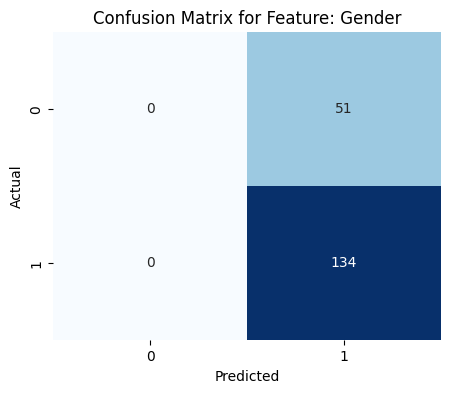

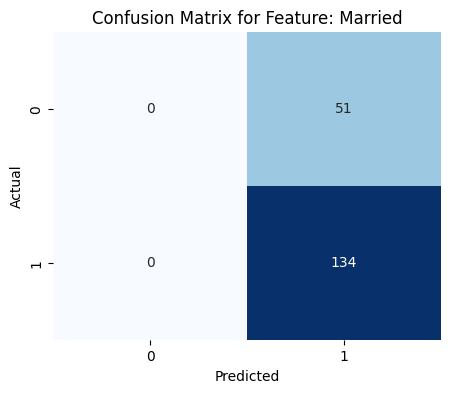

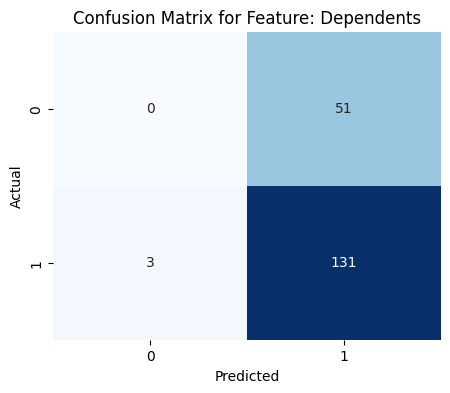

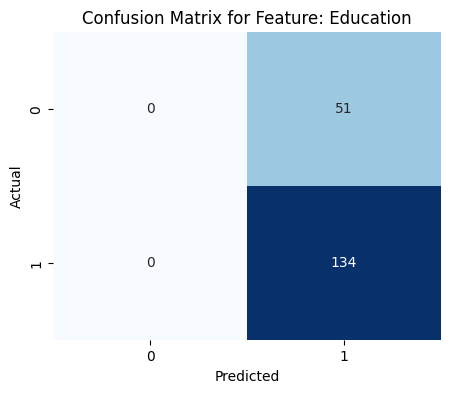

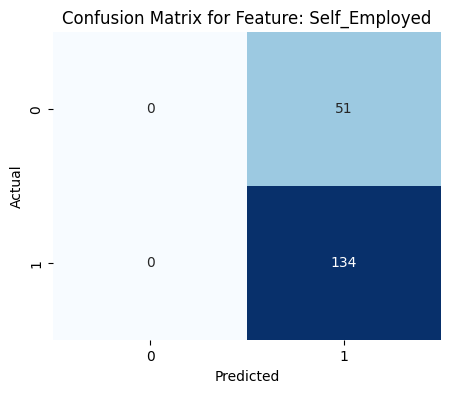

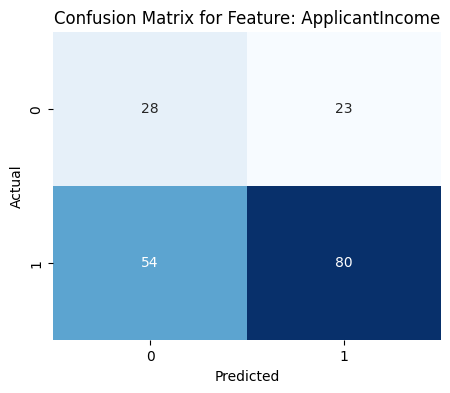

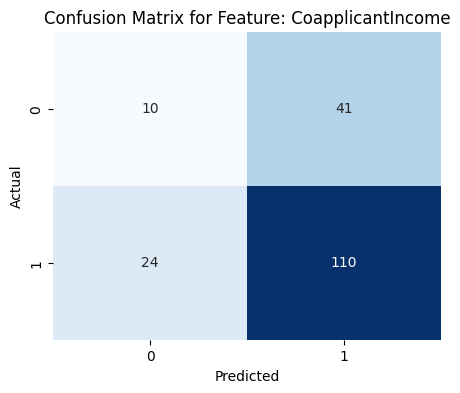

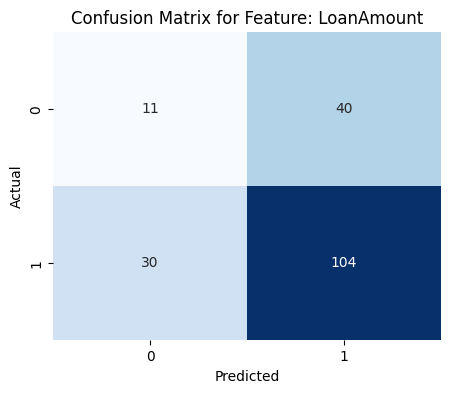

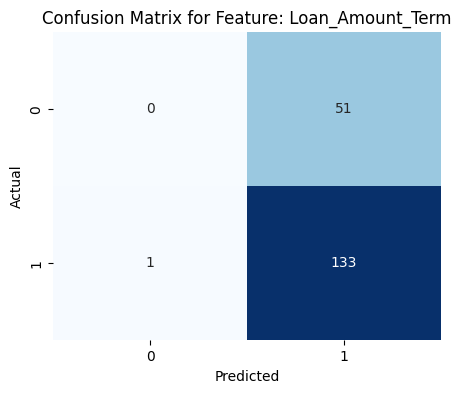

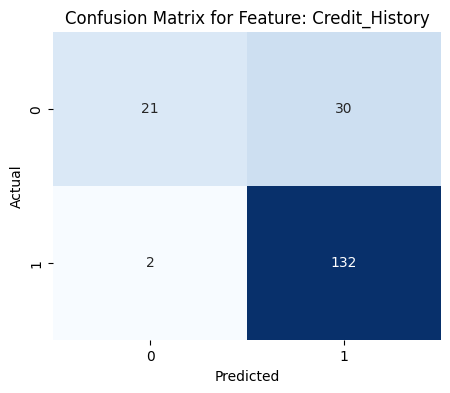

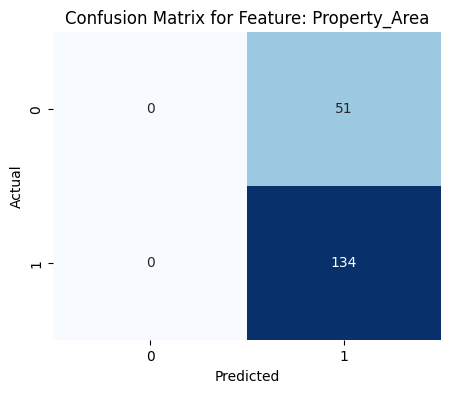

 Single Feature Model Performance Using Decision Tree:

                   Accuracy  Precision  Recall
Credit_History       0.8270     0.8148  0.9851
Married              0.7243     0.7243  1.0000
Gender               0.7243     0.7243  1.0000
Property_Area        0.7243     0.7243  1.0000
Education            0.7243     0.7243  1.0000
Self_Employed        0.7243     0.7243  1.0000
Loan_Amount_Term     0.7189     0.7228  0.9925
Dependents           0.7081     0.7198  0.9776
CoapplicantIncome    0.6486     0.7285  0.8209
LoanAmount           0.6216     0.7222  0.7761
ApplicantIncome      0.5838     0.7767  0.5970

 Best Feature: Credit_History
 Accuracy: 0.827
 Precision: 0.8148
 Recall: 0.9851


In [21]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.preprocessing import OrdinalEncoder
import seaborn as sns
import matplotlib.pyplot as plt

# List all categorical features
all_categorical_features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

# Encode categorical features using OrdinalEncoder
def encode_categorical_features(df, cols):
    ordinal_encoder = OrdinalEncoder()
    df[cols] = ordinal_encoder.fit_transform(df[cols])
    return df

# Apply encoding
df = encode_categorical_features(df, all_categorical_features)

# Define features and label
features = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 
            'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']
label = 'Loan_Status'

# Split the data into train and test sets
X = df[features]
y = df[label]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# Initialize a dictionary to store results
results = {}

# Loop through each feature for evaluation
for feature in features:
    # Extract the feature columns
    X_train_feature = X_train[[feature]]
    X_test_feature = X_test[[feature]]

    # Train a Decision Tree classifier
    model = DecisionTreeClassifier(random_state=0)
    model.fit(X_train_feature, y_train)

    # Make predictions
    predictions = model.predict(X_test_feature)

    # Calculate evaluation metrics
    cm = confusion_matrix(y_test, predictions)
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)

    # Store results
    results[feature] = {
        'Confusion Matrix': cm,
        'Accuracy': round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4)
    }

    # Plot confusion matrix for each feature
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix for Feature: {feature}")
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Convert results to a DataFrame for easier interpretation
results_df = pd.DataFrame({
    feature: {
        'Accuracy': metrics['Accuracy'],
        'Precision': metrics['Precision'],
        'Recall': metrics['Recall']
    } for feature, metrics in results.items()
}).T.sort_values(by='Accuracy', ascending=False)

# Display the results
print(" Single Feature Model Performance Using Decision Tree:\n")
print(results_df)

# Identify the best feature based on accuracy
best_feature = results_df.idxmax()['Accuracy']
print(f"\n Best Feature: {best_feature}")
print(f" Accuracy: {results_df.loc[best_feature, 'Accuracy']}")
print(f" Precision: {results_df.loc[best_feature, 'Precision']}")
print(f" Recall: {results_df.loc[best_feature, 'Recall']}")


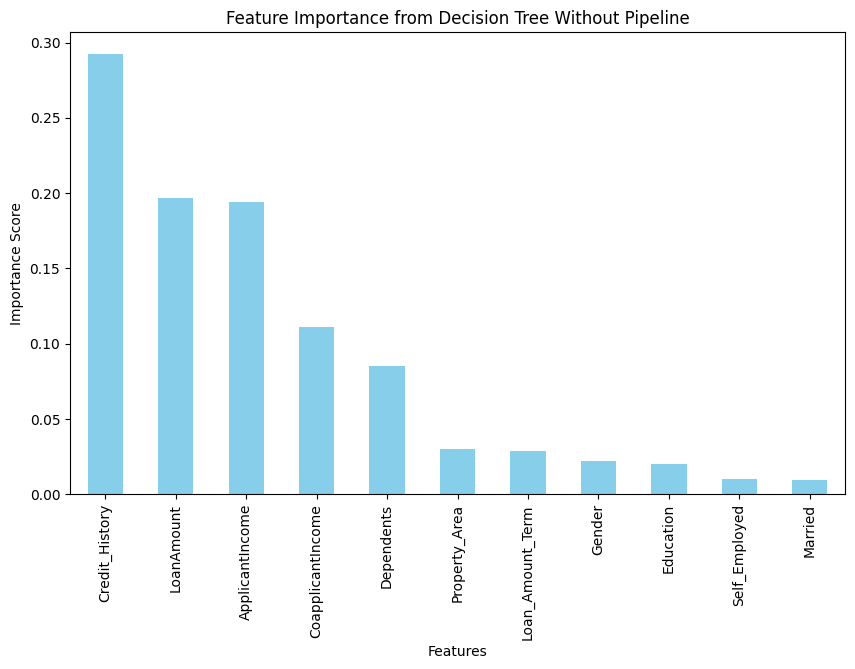

 Most Important Feature: Credit_History
 Feature Importances:
 Credit_History       0.292286
LoanAmount           0.196963
ApplicantIncome      0.193982
CoapplicantIncome    0.111068
Dependents           0.085426
Property_Area        0.029943
Loan_Amount_Term     0.028503
Gender               0.022348
Education            0.019849
Self_Employed        0.010385
Married              0.009246
dtype: float64


In [22]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

# Automatically define features and label
label = 'Loan_Status'
features = df.columns.drop(label)  # Select all columns except the target

# Split the data into training and testing sets (70% train, 30% test)
X = df[features]
y = df[label]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# Train a decision tree on all features directly
model = DecisionTreeClassifier(random_state=0)
model.fit(X_train[features], y_train)

# Get feature importances from DT model
feature_importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)

# Visualize feature importance in a plot
plt.figure(figsize=(10, 6))
feature_importances.plot(kind='bar', color='skyblue')
plt.title('Feature Importance from Decision Tree Without Pipeline')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.show()

# Display most important feature
most_important_feature = feature_importances.idxmax()
print(f" Most Important Feature: {most_important_feature}")
print(" Feature Importances:\n", feature_importances)

**Write your answer here**

I will use Feature Importance and Accuracy and Evaluation Metrics to be through when finding the best feature for classification using Decsion Tree Model.

**Using Evaluation Metrics like accuracy code explanation (looping through features):**
    
I implemented a Decision Tree Classifier to evaluate each feature's ability to independently separate the classes in the loan approval dataset. By training the model using one feature at a time.

The feature that provided the best separation was **Credit_History**, achieving the highest evaluation metrics:

 **Accuracy: 82.7%**  , **82.7%** of loans were correctly classified, for both rejected and approved, very reliable but cannot be trusted alone ( need precision and recall).
 **Precision: 81.5%** , fewer incorrect approvals, percentage is much higher than other features.
 **Recall: 98.5%** , this feature is strong at identifying actual true positives, correct loan approvals.

**Using Feature Importance code explanation (non-looping):**

I used a decison tree classifier because we learned about this model in class and i know that it is great at creating interpretable rules. It splits the dataset based on features that best seperate the target classes at each node. It also uses gini index or information gain/entropy to determine the best feature for splitting.


Features closer to the root of the tree, have more importance. If i use the decision tree model with all the features, I can use feature importance additionally with evaluation metrics like accuracy from looping code, to verify that credit history is influencing the model the most.

Credit_History has the highest importance score, **0.292**, it means this feature consistently helps the model the most to distinguish between loan approvals and rejections during different splits.



## Step 9:

**Revisit Step 2 in your analysis. Identify and implement one preprocessing technique covered in this course that has not been applied yet. Apply this technique to the best-performing model from Step 7 and report its impact on the evaluation metrics.**

*Hint: Think about data points that might significantly deviate from the overall pattern and explore techniques to identify and handle such instances. This step is often useful for improving model performance.*

In [23]:
import pandas as pd

def remove_outliers_iqr(df, columns):
    Q1 = df[columns].quantile(0.25)
    Q3 = df[columns].quantile(0.75)
    IQR = Q3 - Q1

    # multiplier to adjust strength 
    multiplier = 1.5
    # Filter out outliers using negation (keep everyhting that is not what we deem to be an outlier below)
    filtered_df = df[~((df[columns] < (Q1 - multiplier * IQR)) | (df[columns] > (Q3 + multiplier * IQR))).any(axis=1)]
    return filtered_df

# Specify numerical columns for outlier removal
numerical_columns = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

# Remove outliers and update the DataFrame with our new df_cleaned
df_cleaned = remove_outliers_iqr(df, numerical_columns)

df_cleaned.head()




,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,1.0,0.0,0.0,0.0,0.0,5849,0.0,NaN,360.0,1.0,2.0,1
1,1.0,1.0,1.0,0.0,0.0,4583,1508.0,128.0,360.0,1.0,0.0,0
2,1.0,1.0,0.0,0.0,1.0,3000,0.0,66.0,360.0,1.0,2.0,1
3,1.0,1.0,0.0,1.0,0.0,2583,2358.0,120.0,360.0,1.0,2.0,1
4,1.0,0.0,0.0,0.0,0.0,6000,0.0,141.0,360.0,1.0,2.0,1


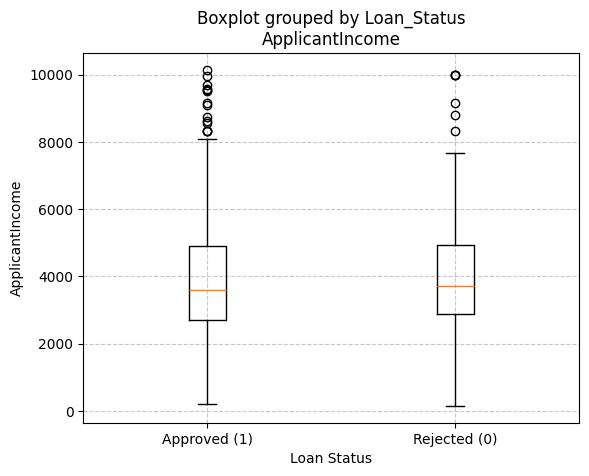

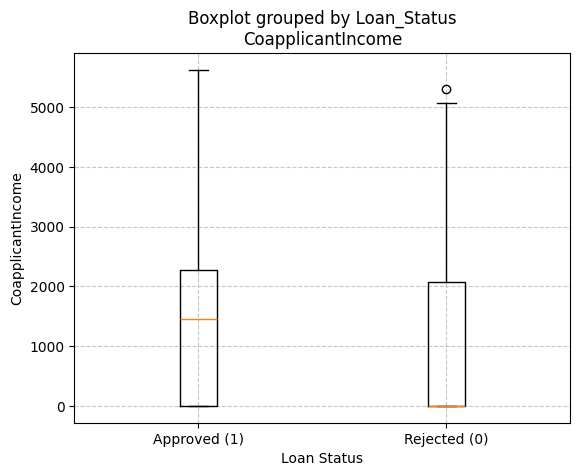

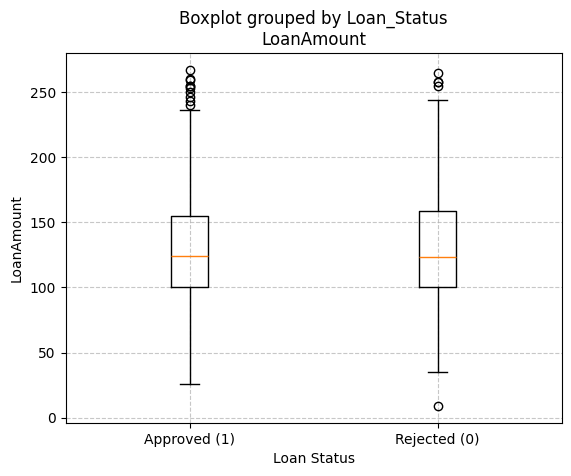

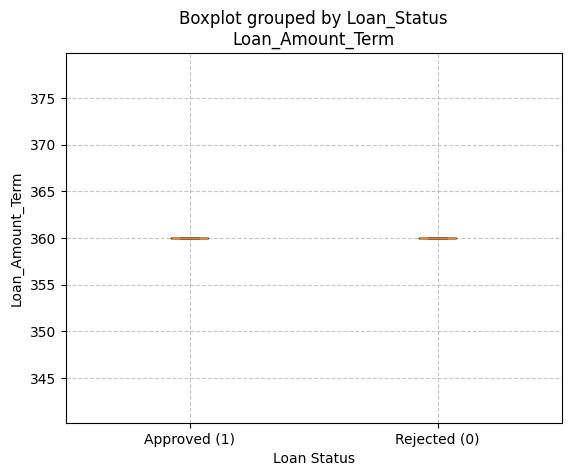

In [24]:
# Let's visualize cleaned data with boxplots to see if we have outliers ourside the min and max. 

import matplotlib.pyplot as plt

# Define the function to plot boxplots
def plot_boxplot(df, col):
    # Drop NaN values to avoid errors
    df_filtered = df[[col, "Loan_Status"]].dropna()

    # Convert categorical-like numerical columns to integer for consistency
    if col in ["Loan_Amount_Term", "Credit_History"]:
        df_filtered[col] = df_filtered[col].astype(int)

    # Separate approved and rejected loans based on encoded 'Loan_Status'
    approved = df_filtered[df_filtered["Loan_Status"] == 1][col]
    rejected = df_filtered[df_filtered["Loan_Status"] == 0][col]

    # Create the boxplot
    plt.boxplot([approved, rejected], tick_labels=["Approved (1)", "Rejected (0)"])
    plt.title(f"Boxplot grouped by Loan_Status\n{col}")
    plt.xlabel("Loan Status")
    plt.ylabel(col)
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.show()

# List of numerical features for boxplot visualization
numeric_features = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

# Apply the function for each numerical feature on the cleaned DataFrame
for col in numeric_features:
    plot_boxplot(df_cleaned, col)


In [25]:
# Separate features and labels
features = df_cleaned.drop('Loan_Status', axis=1)
label = df_cleaned['Loan_Status']

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(features, label, test_size=0.3, random_state=0)


In [26]:
# Import SVM
from sklearn.svm import SVC

# Replace KNN with SVM in the existing pipeline
svc = SVC(kernel='linear', gamma=10)
pipeline.set_params(classifier=svc)


Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('cat1',
                                                  Pipeline(steps=[('ordinal',
                                                                   OrdinalEncoder())]),
                                                  [0, 1, 2, 3, 4]),
                                                 ('cat2',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [10]),
                                                 ('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  [5, 6, 9, 7, 8])])),
                ('imputer',
                 ColumnTransformer(transformers=[('imputer',
                                                  Pipeline(steps=[('imputer0',
                                                                   KNNImputer())]),
                                                  [0, 1, 2, 3, 4, 10, 5, 6, 9,
                                                   7, 8])])),
                ('classifier', SVC(gamma=10, kernel='linear'))])

In [27]:

# Quick NaN cleanup after outlier removal for both train and test sets
X_train = X_train.dropna()
y_train = y_train[X_train.index]  

X_test = X_test.dropna()
y_test = y_test[X_test.index]  


# Check for any NaN values after outlier removal and splitting
print("NaNs in X_train:\n", X_train.isnull().sum())
print("NaNs in X_test:\n", X_test.isnull().sum())


NaNs in X_train:
 Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
dtype: int64
NaNs in X_test:
 Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
dtype: int64


In [28]:
# Train the pipeline on cleaned data
pipeline.fit(X_train, y_train)


# Make predictions
predictions = pipeline.predict(X_test)

# Evaluate model performance
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Print metrics
conf_matrix = confusion_matrix(y_test, predictions)
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)

print("Confusion Matrix:\n", conf_matrix)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)


Confusion Matrix:
 [[14 16]
 [ 1 81]]
Accuracy: 0.8482142857142857
Precision: 0.8350515463917526
Recall: 0.9878048780487805


**Write your answer here**


I have to carefully manage the multiplier, from 0.5 (more extreme) to 1.5 (standard).

Conclusion: 1.5 from the Q1 and Q3 is the best multiplier choice because going too low and going too high results in poor performance. removing all the outliers i can see in the boxplot, will also make the dataset really small.

Accuracy has imporved from 82.7% to 84.82%, Shows some improvement in overall predictions.

Precision improved from 81.5% to 83.5%, model is more reliable than previous non-outlier removed data.

Recall increased from 98.5% to 98.78%, fewer false approvals after outlier removal.

I see a small decrease in true negatives from 21 to 14, meaning SVM with cleaned data without outliers has misclassified more negatives.

False Positives (FP) decreased significantly from 30 to 16, the model now approves fewer unqualified applicants.

SVM is also making fewer incorrect positive predictions.

 Some actual loan approvals may have been removed due to outlier cleaning, meaning fewer approved loans are correctly predicted.

Overall it did improve model performance. SVM is good on smaller datasets but by removing outliers we had make dataset smaller. 

**Something to note for real-world applicability**: If legitimate high-income borrowers were removed as outliers, it could reduce model performance for certain applicant groups.

My assumption for this dataset is to reduce risk and bais for lenders, so outlier removal still helps in risk management.


Maybe next steps would be to implement cross-validation , hyperparamter tuning, balancing the dataset and we can then use PCA analysis.



In [29]:
# Let's try using PCA to idenitfy how much features we really need to train and test the model effectively.

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Transform the data using the existing pipeline without the classifier step
X_train_transformed = pipeline.named_steps['transformer'].fit_transform(X_train)
X_test_transformed = pipeline.named_steps['transformer'].transform(X_test)

# Apply PCA separately
pca = PCA(n_components=2)  # Using 2 components for visualization
X_train_pca = pca.fit_transform(X_train_transformed)
X_test_pca = pca.transform(X_test_transformed)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
print("Explained Variance by Component:", explained_variance)




Explained Variance by Component: [0.26051262 0.19783945]


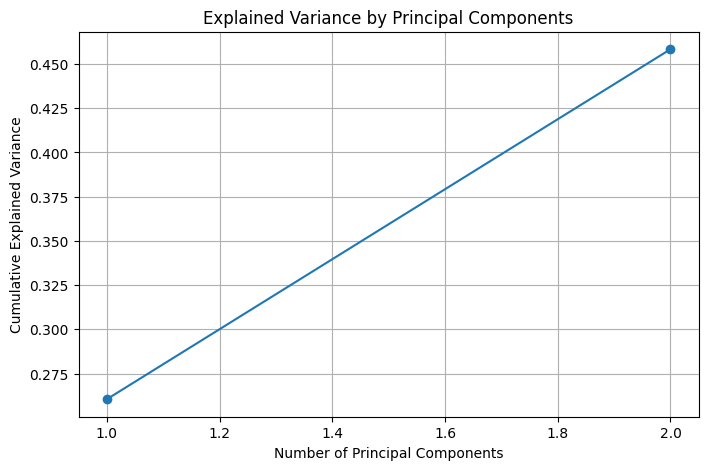

In [30]:
# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance.cumsum(), marker='o')
plt.title('Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()


In [31]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Train SVM on PCA-transformed data
svc = SVC(kernel='linear', gamma=10)
svc.fit(X_train_pca, y_train)

# Predict using the PCA-transformed test set
predictions_pca = svc.predict(X_test_pca)

# Evaluate model performance
conf_matrix_pca = confusion_matrix(y_test, predictions_pca)
accuracy_pca = accuracy_score(y_test, predictions_pca)
precision_pca = precision_score(y_test, predictions_pca)
recall_pca = recall_score(y_test, predictions_pca)

print("Confusion Matrix:\n", conf_matrix_pca)
print(f"Accuracy: {accuracy_pca}")
print(f"Precision: {precision_pca}")
print(f"Recall: {recall_pca}")


Confusion Matrix:
 [[ 0 30]
 [ 0 82]]
Accuracy: 0.7321428571428571
Precision: 0.7321428571428571
Recall: 1.0


- Using just 2 components, has removed a lot of important variance in the dataset that has led to a weaker model.

- We can try to increase the number of principal components to capture more variance.

- we can keep credit history and increase the principal componenents then combine them to see if credit history as we looked at in the previous steps, actually influences the loan approval as we believe.





In [32]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


X_train_transformed = pipeline.named_steps['transformer'].fit_transform(X_train)
X_test_transformed = pipeline.named_steps['transformer'].transform(X_test)

X_train_transformed_df = pd.DataFrame(X_train_transformed)
X_test_transformed_df = pd.DataFrame(X_test_transformed)

X_train_no_ch = X_train_transformed_df.drop(columns=[X_train.columns.get_loc('Credit_History')], axis=1)
X_test_no_ch = X_test_transformed_df.drop(columns=[X_test.columns.get_loc('Credit_History')], axis=1)

# Apply PCA separately
pca = PCA(n_components=2)  # Using 2 components for visualization
X_train_pca = pca.fit_transform(X_train_no_ch)
X_test_pca = pca.transform(X_test_no_ch)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
print("Explained Variance by Component:", explained_variance)


# Add back the Credit_History feature
X_train_final = np.hstack((X_train_pca, X_train['Credit_History'].values.reshape(-1, 1)))
X_test_final = np.hstack((X_test_pca, X_test['Credit_History'].values.reshape(-1, 1)))

Explained Variance by Component: [0.30854439 0.19188308]


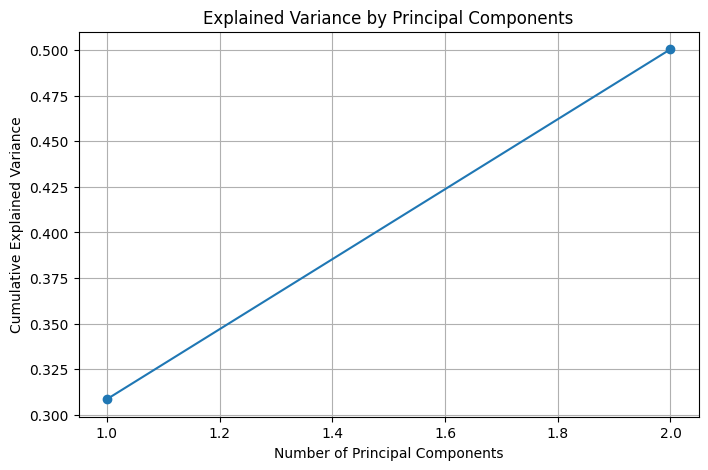

In [33]:
# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance.cumsum(), marker='o')
plt.title('Explained Variance by Principal Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()

In [34]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Train SVM on PCA-transformed data
svc = SVC(kernel='linear', gamma=10)
svc.fit(X_train_pca, y_train)

# Predict using the PCA-transformed test set
predictions_pca = svc.predict(X_test_pca)

# Evaluate model performance
conf_matrix_pca = confusion_matrix(y_test, predictions_pca)
accuracy_pca = accuracy_score(y_test, predictions_pca)
precision_pca = precision_score(y_test, predictions_pca)
recall_pca = recall_score(y_test, predictions_pca)

print("Confusion Matrix:\n", conf_matrix_pca)
print(f"Accuracy: {accuracy_pca}")
print(f"Precision: {precision_pca}")
print(f"Recall: {recall_pca}")


Confusion Matrix:
 [[14 16]
 [ 1 81]]
Accuracy: 0.8482142857142857
Precision: 0.8350515463917526
Recall: 0.9878048780487805


**Conclusion**

For now, I have seen a better balance in performance using more pcs and keepping credit_history. We have retained more of the dataset's variance and our model can be as good at predicting loan approvals as when we did not reduce dimensionality earlier after cleaning outliers but with fewer features. 

This may also make the model faster. I would test this to know for sure.

note: With only 2 components, we are missing out on around 50% of the dataset's variability. This could mean valuable information for loan prediction is being left out.



My next steps after assignment would be to try gaining more variance while keeping performance high or higher than we currently have. do more hyperparamter tuning on SVM and other models and visualize components and other metrics with more complex and richer graphs and visuals.



---

**Note:** The dataset used in this exercise has been adapted from the challenge hosted at [Analytics Vidhya](https://datahack.analyticsvidhya.com/contest/practice-problem-loan-prediction-iii/). As a next step, consider exploring a variety of machine learning models and experimenting with different hyperparameters for each model. Strive to enhance the evaluation metrics, fine-tune your models and visualize the predictions by adapting dimentionality reduction methods like PCA. Additionally, you are encouraged to submit your predictions to the mentioned challenge for a more comprehensive comparison.

For further professional development, consider documenting your work in this Jupyter notebook and upload it to your GitHub account. This practice not only showcases your skills but also serves as a valuable addition to your resume.

Wishing you the best of luck in your endeavors!

---
